# Does claims-data "blindness" bias Arlo's member-level predictions?

## Summary
- **What blindness is:** the model scores a member from claims that arrive late, so conditions the member already has can be missing at quote time and the member is scored as if healthy. It is distinct from new onset and from noise.
- **Why do we care:** Visibility affects calibration. Overall A/E (actual / predicted, six-month actuals annualized, both capped) is 0.685, ranging from 0.86 for members with a claim in the last 30 days to 0.47 for members with no visible claims. The gradient holds within every prediction decile where it can be tested (8 of 8).
- **How:** the score tracks what it can see. Where recent claims are visible it is well calibrated (A/E about 1.0 in the clean cohort); where little is visible it over-predicts (0.59 for no claims). A smaller tail of hidden-condition members is under-predicted: no-visible-claims and 90+ day members hold 70% of members but 44% of the dollars under-predicted by \$10k+.
- **Approach:** joined member-level claim aggregates to the risk scores, compared predictions to annualized live cost with A/E by segment (days since last claim, prediction decile, quote-to-effective gap, age), then checked tail behavior.

## Contents
1. Preliminary EDA (1.1 Load the datasets, 1.2 Descriptive statistics and distributions)
2. Preprocessing (2.1 Column names, 2.2 Claim-level grain, 2.3 Member coverage across files, 2.4 MX/RX presence crosstabs, 2.5 Member-level aggregation, 2.6 Join on MEMBER_TOKEN)
3. Data analysis (3.1 Cleaning, capping and annualizing, 3.2 Days since last claim as a blindness proxy, 3.3 Residuals)
4. Segmentation by A/E (4.1 Segments and metric, 4.2 Reads, 4.3 Tail behavior)
5. Conclusions (findings, evidence, pipeline changes, limits and confidence)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 1. Prelimininary EDA 
### 1.1 Load the datasets

In [2]:
#member file
df_members = pd.read_csv("./MEMBERS.csv")
print(df_members.shape)
df_members.head()

(13376, 10)


,member_token,plan_design_id,program_id,effective_date,age,gender,relationship,state,proposal_generated_time,predictions
0,+/KkejuJ2b3BBOXFlF7c4Wa9G4gBCIM8K+NIdRQorJs=uI...,1,21,2026-01-01,44,M,E,GA,2025-12-16T20:24:21.075Z,3170.409626
1,+/vEiyqS/CzO7gpfYbP99i2nnCcFNprzhfWgePp9Yzs=/W...,1,64,2026-01-01,58,F,E,FL,2025-12-16T17:50:52.140Z,7438.182679
2,+0HmlW5JeAoBXttRdIV1dDS7Vbijn+BzbpBVughwEgk=uj...,1,68,2026-01-01,42,F,E,MO,2025-12-11T16:01:50.014Z,8257.801413
3,+0VzV7f4ZKO8hZlTmBrhUiLtcqaWqcu9xKOpWSHrA1I=AJ...,1,68,2026-01-01,42,M,E,IL,2025-12-18T01:46:08.371Z,5078.465602
4,+0VzV7f4ZKO8hZlTmBrhUiLtcqaWqcu9xKOpWSHrA1I=h9...,1,68,2026-01-01,42,M,E,IL,2025-10-14T07:58:55.379Z,5078.465602


In [3]:
#inference files for MX and RX
df_infer_MX = pd.read_csv("./INFERENCE_MX_CLAIMLINES.csv")
df_infer_RX = pd.read_csv("./INFERENCE_RX_CLAIMS.csv")
print(f"Shape for Inference: MX -> {df_infer_MX.shape}, RX -> {df_infer_RX.shape}")
df_infer_MX.head()

C:\Users\ajati\AppData\Local\Temp\ipykernel_3312\1945507995.py:2: DtypeWarning: Columns (44: DRG) have mixed types. Specify dtype option on import or set low_memory=False.
  df_infer_MX = pd.read_csv("./INFERENCE_MX_CLAIMLINES.csv")


Shape for Inference: MX -> (83919, 56), RX -> (53092, 37)


C:\Users\ajati\AppData\Local\Temp\ipykernel_3312\1945507995.py:3: DtypeWarning: Columns (17: NDC) have mixed types. Specify dtype option on import or set low_memory=False.
  df_infer_RX = pd.read_csv("./INFERENCE_RX_CLAIMS.csv")


,A_claimline_id,MEMBER_TOKEN,SOURCE_MEMBER_ID,SOURCE_SUBSCRIBER_ID,SOURCE_CLAIM_ID,SOURCE_CLAIMLINE_ID,CLAIM_TYPE,CLAIM_STATUS,ALLOWED_AMOUNT,BILLED_AMOUNT,...,PLACE_OF_SERVICE_CODE,PRINCIPAL_PROCEDURE_CODE,PROCEDURE_CODE,PROCEDURE_MODIFIER_1,PROCEDURE_MODIFIER_2,QUANTITY,REVENUE_CODE,UNITS,COORDINATION_OF_BENEFIT_AMOUNT,IP_OP
0,cae70b4e5d02b11564a469658b707241,alrUUA3pO+IjocUDpGwfxt4H79ni/iILX+stxDOihaw=3K...,e1f70eec4307a24f24ffe31f7f583abc83f3adf92b4b58...,NaN,cae70b4e5d02b11564a469658b70724,1,NaN,NaN,580.3,580.3,...,NaN,80053,80053,NaN,NaN,1.0,300.0,NaN,NaN,OP
1,cae70b4e5d02b11564a469658b7072410,alrUUA3pO+IjocUDpGwfxt4H79ni/iILX+stxDOihaw=3K...,e1f70eec4307a24f24ffe31f7f583abc83f3adf92b4b58...,NaN,cae70b4e5d02b11564a469658b70724,10,NaN,NaN,386.3,386.3,...,NaN,80053,88305,NaN,NaN,1.0,310.0,NaN,NaN,OP
2,cae70b4e5d02b11564a469658b7072411,alrUUA3pO+IjocUDpGwfxt4H79ni/iILX+stxDOihaw=3K...,e1f70eec4307a24f24ffe31f7f583abc83f3adf92b4b58...,NaN,cae70b4e5d02b11564a469658b70724,11,NaN,NaN,162.2,162.2,...,NaN,80053,88311,NaN,NaN,1.0,310.0,NaN,NaN,OP
3,cae70b4e5d02b11564a469658b7072412,alrUUA3pO+IjocUDpGwfxt4H79ni/iILX+stxDOihaw=3K...,e1f70eec4307a24f24ffe31f7f583abc83f3adf92b4b58...,NaN,cae70b4e5d02b11564a469658b70724,12,NaN,NaN,329.9,329.9,...,NaN,80053,88313,NaN,NaN,1.0,310.0,NaN,NaN,OP
4,cae70b4e5d02b11564a469658b7072413,alrUUA3pO+IjocUDpGwfxt4H79ni/iILX+stxDOihaw=3K...,e1f70eec4307a24f24ffe31f7f583abc83f3adf92b4b58...,NaN,cae70b4e5d02b11564a469658b70724,13,NaN,NaN,1343.0,1343.0,...,NaN,80053,88341,59,NaN,2.0,310.0,NaN,NaN,OP


In [4]:
df_infer_MX.head()

,A_claimline_id,MEMBER_TOKEN,SOURCE_MEMBER_ID,SOURCE_SUBSCRIBER_ID,SOURCE_CLAIM_ID,SOURCE_CLAIMLINE_ID,CLAIM_TYPE,CLAIM_STATUS,ALLOWED_AMOUNT,BILLED_AMOUNT,...,PLACE_OF_SERVICE_CODE,PRINCIPAL_PROCEDURE_CODE,PROCEDURE_CODE,PROCEDURE_MODIFIER_1,PROCEDURE_MODIFIER_2,QUANTITY,REVENUE_CODE,UNITS,COORDINATION_OF_BENEFIT_AMOUNT,IP_OP
0,cae70b4e5d02b11564a469658b707241,alrUUA3pO+IjocUDpGwfxt4H79ni/iILX+stxDOihaw=3K...,e1f70eec4307a24f24ffe31f7f583abc83f3adf92b4b58...,NaN,cae70b4e5d02b11564a469658b70724,1,NaN,NaN,580.3,580.3,...,NaN,80053,80053,NaN,NaN,1.0,300.0,NaN,NaN,OP
1,cae70b4e5d02b11564a469658b7072410,alrUUA3pO+IjocUDpGwfxt4H79ni/iILX+stxDOihaw=3K...,e1f70eec4307a24f24ffe31f7f583abc83f3adf92b4b58...,NaN,cae70b4e5d02b11564a469658b70724,10,NaN,NaN,386.3,386.3,...,NaN,80053,88305,NaN,NaN,1.0,310.0,NaN,NaN,OP
2,cae70b4e5d02b11564a469658b7072411,alrUUA3pO+IjocUDpGwfxt4H79ni/iILX+stxDOihaw=3K...,e1f70eec4307a24f24ffe31f7f583abc83f3adf92b4b58...,NaN,cae70b4e5d02b11564a469658b70724,11,NaN,NaN,162.2,162.2,...,NaN,80053,88311,NaN,NaN,1.0,310.0,NaN,NaN,OP
3,cae70b4e5d02b11564a469658b7072412,alrUUA3pO+IjocUDpGwfxt4H79ni/iILX+stxDOihaw=3K...,e1f70eec4307a24f24ffe31f7f583abc83f3adf92b4b58...,NaN,cae70b4e5d02b11564a469658b70724,12,NaN,NaN,329.9,329.9,...,NaN,80053,88313,NaN,NaN,1.0,310.0,NaN,NaN,OP
4,cae70b4e5d02b11564a469658b7072413,alrUUA3pO+IjocUDpGwfxt4H79ni/iILX+stxDOihaw=3K...,e1f70eec4307a24f24ffe31f7f583abc83f3adf92b4b58...,NaN,cae70b4e5d02b11564a469658b70724,13,NaN,NaN,1343.0,1343.0,...,NaN,80053,88341,59,NaN,2.0,310.0,NaN,NaN,OP


In [5]:
#live files for MX and RX
df_live_MX = pd.read_csv("./LIVE_MX_CLAIMLINES.csv")
df_live_RX = pd.read_csv("./LIVE_RX_CLAIMS.csv")
print(f"Shape for Live: MX -> {df_live_MX.shape}, RX -> {df_live_RX.shape}")
df_live_MX.head()

C:\Users\ajati\AppData\Local\Temp\ipykernel_3312\4222147280.py:2: DtypeWarning: Columns (21: PROCEDURE_MODIFIER_2, 30: DIAGNOSIS_CODE_7, 31: DIAGNOSIS_CODE_8, 32: DIAGNOSIS_CODE_9, 33: DIAGNOSIS_CODE_10, 34: DIAGNOSIS_CODE_11, 35: DIAGNOSIS_CODE_12, 47: PLAN_WITHHELD_REASON, 49: IS_IN_NETWORK) have mixed types. Specify dtype option on import or set low_memory=False.
  df_live_MX = pd.read_csv("./LIVE_MX_CLAIMLINES.csv")


Shape for Live: MX -> (128490, 55), RX -> (59110, 35)


C:\Users\ajati\AppData\Local\Temp\ipykernel_3312\4222147280.py:3: DtypeWarning: Columns (19: IS_SPECIALTY, 20: IS_RETAIL, 28: PHARMACY_NAME, 32: PRESCRIBING_PHYSICIAN_ORGANIZATION_NAME, 34: a_claim_id) have mixed types. Specify dtype option on import or set low_memory=False.
  df_live_RX = pd.read_csv("./LIVE_RX_CLAIMS.csv")


,MEMBER_TOKEN,SOURCE_CLAIMLINE_NUMBER,CLAIM_TYPE,CLAIM_STATUS,CLAIMLINE_FROM_DATE,CLAIMLINE_TO_DATE,CLAIM_FROM_DATE,CLAIM_TO_DATE,PAID_DATE,ADMISSION_DATE,...,DEDUCTIBLE_AMOUNT,PLAN_WITHHELD_AMOUNT,PLAN_WITHHELD_REASON,COB_AMOUNT,IS_IN_NETWORK,BILLING_PROVIDER_NAME,BILLING_PROVIDER_NPI,BILLING_PROVIDER_TAX_ID,BILLING_PROVIDER_ZIP,a_claimline_id
0,35MEY0uWHxLVuJkO9LIeO+EXWqQ5QkIe01K74He7GmQ=lf...,1,MEDICAL,PAID,2026-03-26,2026-03-26,2026-03-26,2026-03-26,2026-04-15,2026-03-26,...,0.0,0.0,NaN,0.0,True,NaN,NaN,NaN,60463.0,2026-100000042-01
1,7KQNtPRLOJFSYXqzblIxbQ7JI8UEluc6+kNpqHLo7Yk=9r...,4,MEDICAL,PAID,2026-03-25,2026-03-25,2026-03-25,2026-03-25,2026-04-15,2026-03-25,...,13.5,0.0,NaN,0.0,True,NaN,NaN,NaN,76118.0,2026-100000068-04
2,1jjF9x9LKe38/gbq7D22GYyFJLut+cewyxDe4mL8/Qs=j3...,1,MEDICAL,PAID,2026-03-19,2026-03-19,2026-03-19,2026-03-19,2026-04-15,2026-03-19,...,0.0,0.0,NaN,0.0,True,NaN,NaN,NaN,75284.0,2026-100000147-01
3,1jjF9x9LKe38/gbq7D22GYyFJLut+cewyxDe4mL8/Qs=j3...,2,MEDICAL,PAID,2026-03-19,2026-03-19,2026-03-19,2026-03-19,2026-04-15,2026-03-19,...,0.0,0.0,NaN,0.0,True,NaN,NaN,NaN,75284.0,2026-100000147-02
4,eAZsSZcddR8uZ1pKo4hDGlDkW/gZ5reBNGPgnH5qUGs=Qd...,2,MEDICAL,PAID,2026-03-31,2026-03-31,2026-03-17,2026-03-31,2026-05-18,2026-03-17,...,414.4,0.0,NaN,0.0,True,NaN,NaN,NaN,77404.0,2026-100000269-02


In [6]:
df_live_RX.head()

,MEMBER_TOKEN,CLAIM_TYPE,CLAIM_STATUS,FILL_DATE,PAID_DATE,AWP,ALLOWED_AMOUNT,DISPENSING_FEE_AMOUNT,INGREDIENT_COST_AMOUNT,SALES_TAX_AMOUNT,...,QUANTITY,DAYS_SUPPLY,PHARMACY_NPI,PHARMACY_NAME,PHARMACY_ZIP,PHARMACY_TIN,PRESCRIBING_PHYSICIAN_NPI,PRESCRIBING_PHYSICIAN_ORGANIZATION_NAME,PRESCRIBING_PHYSICIAN_ZIP,a_claim_id
0,f9NYSKFCatQVwQBjbyulHWA9d3uYzV9QgstnA9BpKEk=uF...,RX,PAID,2026-01-01,NaN,NaN,1095.36,1.0,1094.36,0.00,...,2.0,28.0,1.932585e+09,WALMART PHARMACY 10-4618,77573.0,NaN,1.619901e+09,AMIR SALIM,NaN,1222329506
1,fZqY/Q+YMlyO5tzw9QzdXNUvJSLKQpyPkg7c2FxhGlw=/v...,RX,PAID,2026-01-01,NaN,NaN,16.92,1.0,15.92,0.00,...,14.0,7.0,1.326148e+09,CVS PHARMACY #01889,2135.0,NaN,1.790348e+09,JAMIE DELMONTE,NaN,1222344643
2,2sT2cOe7G7FyLeshJOjFTnk5FudHJIHyGHcUbkjUS0w=Kt...,RX,PAID,2026-01-01,NaN,NaN,4.00,0.0,4.00,0.00,...,100.0,90.0,1.386985e+09,WALMART PHARMACY 10-3015,75227.0,NaN,1.487388e+09,SARAH OUIMET,NaN,1222388595
3,eTTuRZZQZF/mybbVpZue6CBD/B2k1y0NqiOS5dGFewk=8b...,RX,PAID,2026-01-01,NaN,NaN,20.92,1.0,19.92,0.00,...,60.0,30.0,1.295752e+09,WALMART PHARMACY 10-1576,46375.0,NaN,1.629012e+09,MUHAMMAD KUDAIMI,NaN,1222466433
4,2Nj9v98lAZRRcTnTXBnnPHDnVpObZ5LTcbLLGr6+nhI=hu...,RX,PAID,2026-01-02,NaN,NaN,19.10,1.0,17.82,0.28,...,30.0,30.0,1.710995e+09,WALGREENS #07829,60446.0,NaN,1.134182e+09,SANJAY PETHKAR,NaN,1222474891


### 1.2 Descriptive stats, distributions, visual representations

In [7]:
#first, let's look at the member file. What does the distribution of scores look like?
#is it a skewed? what's the mean? Is transformation necessary for better dynamic range?
df_members.describe()

,plan_design_id,program_id,age,predictions
count,13376.0,13376.000000,13376.000000,13376.000000
mean,1.0,37.597189,35.842105,7396.846573
std,0.0,23.201611,17.781394,10488.097649
min,1.0,1.000000,-49.000000,1067.883239
25%,1.0,14.000000,23.000000,3325.299468
50%,1.0,44.000000,36.000000,5655.798775
75%,1.0,63.000000,50.000000,8177.376727
max,1.0,70.000000,97.000000,437246.253484


In [8]:
print(f"Number of NaN preds = {df_members.predictions.isna().sum()}")

Number of NaN preds = 0


#### At first glance, the max predictions is 40k, which is several standard deviations from the mean. Predicted annual claims cost are likely right skewed where mean > median >= mode because we would primarily have low-risk folks, but a few high-risk individuals would raise the mean. 

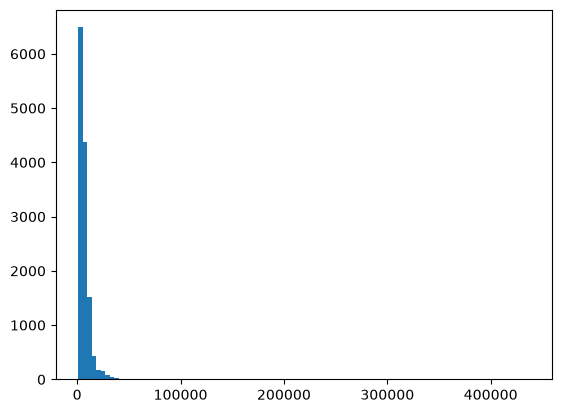

In [9]:
plt.hist(df_members.predictions, bins = 100);

#### a log-distribution of predictions might make more sense!

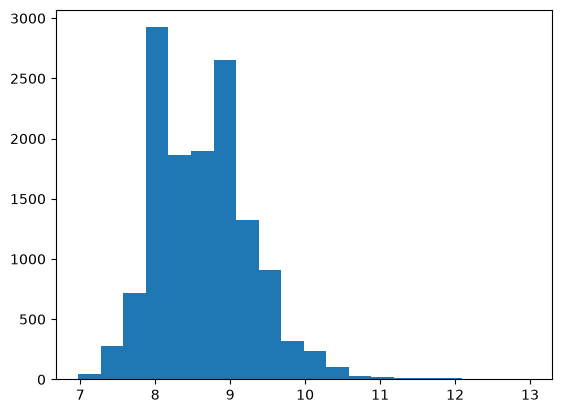

In [10]:
plt.hist(np.log(df_members.predictions), bins = 20);

#### we've established that we might want to work with log-transform of scores (although I want to revisit this later). Might also want to see what score distributions look like by age bins

In [11]:
print(f"Number of NaN ages = {df_members.age.isna().sum()}")
print(f"Number of invalid ages = {df_members[df_members.age<=0].age.count()}") #you could file
    #claims for a baby but negative would make no sense. We will filter these out

Number of NaN ages = 0
Number of invalid ages = 106


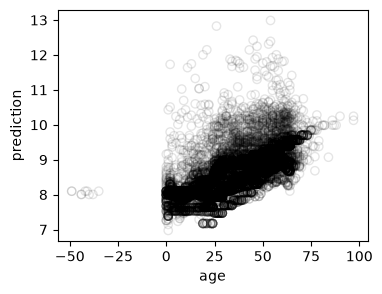

In [12]:
fig, ax = plt.subplots(figsize = (4,3))
ax.scatter(df_members.age, np.log(df_members.predictions), facecolor = "None", edgecolor = "k", alpha = .1)
ax.set_xlabel("age")
ax.set_ylabel("prediction");

#### claims prediction amounts correlate with age, which makes sense as risks are higher at later age

#### let's take a quick look at gender, as well

In [13]:
df_members.gender.value_counts()

gender
M    6850
F    6526
Name: count, dtype: int64

## 2. Preproc
### 2.1 First off, rename columns to match before any join there are case issues (like for MEMBER_TOKEN)

In [14]:
def rename_cols(df):
    cols = df.columns
    cols_upper = [i.upper() for i in cols]
    dict_cols = dict(zip(cols, cols_upper))
    df.rename(columns = dict_cols, inplace=True)
    return df

df_live_MX = rename_cols(df_live_MX)
df_live_RX = rename_cols(df_live_RX)
df_infer_MX = rename_cols(df_infer_MX)
df_infer_RX = rename_cols(df_infer_RX)
df_members = rename_cols(df_members)

C:\Users\ajati\AppData\Local\Temp\ipykernel_3312\3962002388.py:5: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns = dict_cols, inplace=True)


In [15]:
#double check
df_members.columns

Index(['MEMBER_TOKEN', 'PLAN_DESIGN_ID', 'PROGRAM_ID', 'EFFECTIVE_DATE', 'AGE',
       'GENDER', 'RELATIONSHIP', 'STATE', 'PROPOSAL_GENERATED_TIME',
       'PREDICTIONS'],
      dtype='str')

In [16]:
#for MX, source_claimline_number -> source_claimline_id
df_live_MX.rename(columns = {"SOURCE_CLAIMLINE_NUMBER": "SOURCE_CLAIMLINE_ID"}, inplace=True)

C:\Users\ajati\AppData\Local\Temp\ipykernel_3312\1523952358.py:2: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_live_MX.rename(columns = {"SOURCE_CLAIMLINE_NUMBER": "SOURCE_CLAIMLINE_ID"}, inplace=True)


### 2.2 Going through data dictionary, RX data is already at claims level.
- MX infer has claim id
- MX live does not
  
We can find common unique columns in both, map to claim id from infer and then apply to live. 

In [17]:
print(f"Common MX columns are {set(df_infer_MX.columns.tolist()) & set(df_live_MX.columns.tolist())}")

Common MX columns are {'DIAGNOSIS_CODE_8', 'A_CLAIMLINE_ID', 'DIAGNOSIS_CODE_15', 'CLAIM_FROM_DATE', 'COPAY_AMOUNT', 'CLAIMLINE_FROM_DATE', 'DIAGNOSIS_CODE_11', 'DIAGNOSIS_CODE_16', 'DIAGNOSIS_CODE_14', 'REVENUE_CODE', 'PROCEDURE_MODIFIER_1', 'CLAIMLINE_TO_DATE', 'DIAGNOSIS_CODE_7', 'DIAGNOSIS_CODE_1', 'QUANTITY', 'PRINCIPAL_PROCEDURE_CODE', 'BILLING_PROVIDER_ZIP', 'ADMISSION_DATE', 'PLAN_PAID_AMOUNT', 'CLAIM_TO_DATE', 'COINSURANCE_AMOUNT', 'BILL_TYPE', 'DIAGNOSIS_CODE_6', 'PLACE_OF_SERVICE_CODE', 'BILLED_AMOUNT', 'CLAIM_TYPE', 'IS_IN_NETWORK', 'DIAGNOSIS_CODE_10', 'SOURCE_CLAIMLINE_ID', 'DIAGNOSIS_CODE_9', 'DISCHARGE_DATE', 'BILLING_PROVIDER_TAX_ID', 'MEMBER_TOKEN', 'CLAIM_STATUS', 'CLAIM_INSTITUTIONAL_OR_PROFESSIONAL', 'PROCEDURE_CODE', 'IP_OP', 'BILLING_PROVIDER_NAME', 'BILLING_PROVIDER_NPI', 'DIAGNOSIS_CODE_12', 'DIAGNOSIS_CODE_5', 'DIAGNOSIS_CODE_2', 'ALLOWED_AMOUNT', 'PROCEDURE_MODIFIER_2', 'DIAGNOSIS_CODE_3', 'DEDUCTIBLE_AMOUNT', 'PAID_DATE', 'DIAGNOSIS_CODE_13', 'DRG', 'DIAGNOS

#### Based on what we see above, we could use MEMBER_TOKEN, CLAIMLINE_FROM_DATA, DIAGNOSIS_CODE_1, IP_OP to construct an ID that must map 1:1 to claim_id
#### Used the above columns because they have 100% or near 100% fill

In [18]:
proxy_CLAIM_ID = (df_infer_MX.groupby(['MEMBER_TOKEN', 'CLAIMLINE_FROM_DATE', 'DIAGNOSIS_CODE_1', 'QUANTITY'], sort=False).ngroup() + 1)
print(len(proxy_CLAIM_ID.unique()))
print(len(df_infer_MX.SOURCE_CLAIM_ID.unique()))

33924
33058


In [19]:
print(len(df_live_MX.MEMBER_TOKEN.values.unique()),
    len(set(df_live_MX.MEMBER_TOKEN.values) & set(df_infer_MX.MEMBER_TOKEN.values)))

6063 3137


#### In interest of time, abandon claimline to claim aggregation <- this is something I would probably spend more time on in reality

### 2.3 Important question: does members have all the members across RX and MX?

In [20]:
print(f"Number of unique members in MEMBER file {len(df_members.MEMBER_TOKEN.unique())}\n\
Number of unique members in MX LIVE file {len(df_live_MX.MEMBER_TOKEN.unique())} of which {len(set(df_live_MX.MEMBER_TOKEN.values) & set(df_members.MEMBER_TOKEN.values))} in MEMBERS file\n\
Number of unique members in MX INFER file {len(df_infer_MX.MEMBER_TOKEN.unique())} of which {len(set(df_infer_MX.MEMBER_TOKEN.values) & set(df_members.MEMBER_TOKEN.values))} in MEMBERS file \n\
Number of unique members in RX LIVE file {len(df_live_RX.MEMBER_TOKEN.unique())} of which {len(set(df_live_RX.MEMBER_TOKEN.values) & set(df_members.MEMBER_TOKEN.values))} in MEMBERS file\n\
Number of unique members in RX INFER file {len(df_infer_RX.MEMBER_TOKEN.unique())} of which {len(set(df_infer_RX.MEMBER_TOKEN.values) & set(df_members.MEMBER_TOKEN.values))} in MEMBERS file")

Number of unique members in MEMBER file 13376
Number of unique members in MX LIVE file 6063 of which 6063 in MEMBERS file
Number of unique members in MX INFER file 5443 of which 5443 in MEMBERS file 
Number of unique members in RX LIVE file 4936 of which 4936 in MEMBERS file
Number of unique members in RX INFER file 3456 of which 3456 in MEMBERS file


#### Great! So member file has all member info as needed.

### 2.4 Work with members data. Are there members with no MX/RX memberships? Are there members who have MX but not RX claims, or vice versa, or both? 

In [21]:
df_members["RX_infer_tag"] = df_members.MEMBER_TOKEN.isin(df_infer_RX.MEMBER_TOKEN)
df_members["MX_infer_tag"] = df_members.MEMBER_TOKEN.isin(df_infer_MX.MEMBER_TOKEN)
df_members["RX_live_tag"] = df_members.MEMBER_TOKEN.isin(df_live_RX.MEMBER_TOKEN)
df_members["MX_live_tag"] = df_members.MEMBER_TOKEN.isin(df_live_MX.MEMBER_TOKEN)
df_members.head()

,MEMBER_TOKEN,PLAN_DESIGN_ID,PROGRAM_ID,EFFECTIVE_DATE,AGE,GENDER,RELATIONSHIP,STATE,PROPOSAL_GENERATED_TIME,PREDICTIONS,RX_infer_tag,MX_infer_tag,RX_live_tag,MX_live_tag
0,+/KkejuJ2b3BBOXFlF7c4Wa9G4gBCIM8K+NIdRQorJs=uI...,1,21,2026-01-01,44,M,E,GA,2025-12-16T20:24:21.075Z,3170.409626,False,False,True,True
1,+/vEiyqS/CzO7gpfYbP99i2nnCcFNprzhfWgePp9Yzs=/W...,1,64,2026-01-01,58,F,E,FL,2025-12-16T17:50:52.140Z,7438.182679,False,True,True,False
2,+0HmlW5JeAoBXttRdIV1dDS7Vbijn+BzbpBVughwEgk=uj...,1,68,2026-01-01,42,F,E,MO,2025-12-11T16:01:50.014Z,8257.801413,False,False,False,False
3,+0VzV7f4ZKO8hZlTmBrhUiLtcqaWqcu9xKOpWSHrA1I=AJ...,1,68,2026-01-01,42,M,E,IL,2025-12-18T01:46:08.371Z,5078.465602,False,False,True,False
4,+0VzV7f4ZKO8hZlTmBrhUiLtcqaWqcu9xKOpWSHrA1I=h9...,1,68,2026-01-01,42,M,E,IL,2025-10-14T07:58:55.379Z,5078.465602,False,False,False,False


In [22]:
sum_all = df_members[["RX_infer_tag", "MX_infer_tag", "RX_live_tag", "MX_live_tag"]].sum(axis=1)
df_members["num_MX_RX_membership"] = sum_all
df_members.num_MX_RX_membership.value_counts()

num_MX_RX_membership
0    3903
1    3164
2    3084
3    2334
4     891
Name: count, dtype: int64

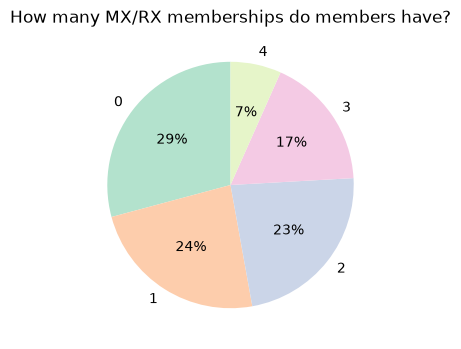

In [23]:
membership_counts = (df_members["num_MX_RX_membership"].value_counts().sort_index())

plt.figure(figsize=(4, 4))
plt.pie(membership_counts.values, labels=membership_counts.index, autopct='%1.0f%%',\
        startangle = 90, colors=plt.cm.Pastel2.colors)

plt.title("How many MX/RX memberships do members have?")
plt.show()

#### Now we can create crosstabs!

In [24]:
pd.crosstab(df_members.RX_live_tag, df_members.RX_infer_tag, margins=True)

RX_infer_tag,False,True,All
RX_live_tag,,,
False,6612,1828,8440
True,3308,1628,4936
All,9920,3456,13376


In [25]:
pd.crosstab(df_members.MX_live_tag, df_members.MX_infer_tag, margins=True)

MX_infer_tag,False,True,All
MX_live_tag,,,
False,5007,2306,7313
True,2926,3137,6063
All,7933,5443,13376


In [26]:
pd.crosstab(df_members.MX_live_tag, df_members.RX_live_tag, margins=True)

RX_live_tag,False,True,All
MX_live_tag,,,
False,6671,642,7313
True,1769,4294,6063
All,8440,4936,13376


In [27]:
pd.crosstab(df_members.MX_infer_tag, df_members.RX_infer_tag, margins=True)

RX_infer_tag,False,True,All
MX_infer_tag,,,
False,6356,1577,7933
True,3564,1879,5443
All,9920,3456,13376


In [28]:
pd.crosstab(df_members.MX_infer_tag | df_members.RX_infer_tag,\
            df_members.MX_live_tag | df_members.RX_live_tag, margins=True,
            rownames=['All Infer'], colnames=['All Live'])

All Live,False,True,All
All Infer,,,
False,3903,2453,6356
True,2768,4252,7020
All,6671,6705,13376


#### In the last crosstab we see that there are 3903 records that are fully NULL, as we know. There are 4252 records that have both live and infered records

### 2.5 Want to join, but before getting there we need to establish granularity. Everything is done on member level
#### Let's aggregate the inference datasets coalescing claims/claimlines, keeping only the aggregated information we'd need @ member level. Do it for RX and MX infer and then move to live:

#### Choose fields that have high fill value and could be found in both live and infer

#### 1. MX Infer:
- how many claimlines per member? how many claims?
- what is the max claim?
- what is the max/tot/mean allowed?
- what is the max/tot/mean billed amt?
- how many providers?

In [29]:
df_infer_MX_grouped = df_infer_MX.groupby("MEMBER_TOKEN").agg(
    MX_claimline_count = ("A_CLAIMLINE_ID", "count"),
    MX_claim_count = ("SOURCE_CLAIM_ID", "nunique"),
    MX_allowed_sum = ("ALLOWED_AMOUNT", "sum"),
    MX_allowed_mean = ("ALLOWED_AMOUNT", "mean"),
    MX_allowed_max = ("ALLOWED_AMOUNT", "max"),
    MX_billed_sum = ("BILLED_AMOUNT", "sum"),
    MX_billed_mean = ("BILLED_AMOUNT", "mean"),
    MX_billed_max = ("BILLED_AMOUNT", "max"),
    MX_provider_count = ("BILLING_PROVIDER_NPI", "nunique")).reset_index()
df_infer_MX_grouped.head()

,MEMBER_TOKEN,MX_claimline_count,MX_claim_count,MX_allowed_sum,MX_allowed_mean,MX_allowed_max,MX_billed_sum,MX_billed_mean,MX_billed_max,MX_provider_count
0,+/vEiyqS/CzO7gpfYbP99i2nnCcFNprzhfWgePp9Yzs=/W...,9,7,1309.00,145.444444,375.00,1309.00,145.444444,375.00,2
1,+0qHNvpfiY97coL7tnzcA6ApTWPJhXlHTJL85bZRpcA=li...,103,16,121478.34,1179.401359,21340.00,121478.34,1179.401359,21340.00,9
2,+1iYFH01GgZCmip+kgfH9dW79xfh0EDK0tK0ukJJxAY=5D...,5,2,1185.00,237.000000,300.00,1185.00,237.000000,300.00,1
3,+3+uYvHFGMqOm3tHmDtvVKdESv4/Y/UU8IQmbgdh3NQ=6N...,7,3,4579.66,654.237143,2090.00,4579.66,654.237143,2090.00,2
4,+31DfQm1W4XaG+mSSu4phBW3bsQ+y76plIWd8PJ2XrQ=Cl...,10,3,1612.87,161.287000,478.67,1612.87,161.287000,478.67,2


#### 2. RX Infer 
- how many claims?
- what is the max/tot/mean allowed?
- how many unique drugs (via NDC)?
- mean/tot days of supply
- mean/tot quantity

In [30]:
df_infer_RX_grouped = (df_infer_RX.groupby("MEMBER_TOKEN").agg(
    RX_claim_count = ("A_CLAIM_ID", "count"),
    RX_allowed_sum = ("ALLOWED_AMOUNT", "sum"),
    RX_allowed_mean = ("ALLOWED_AMOUNT", "mean"),
    RX_allowed_max = ("ALLOWED_AMOUNT", "max"),
    RX_unique_drugs = ("NDC", "nunique"),
    RX_unique_prescriber = ("PRESCRIBING_PHYSICIAN_NPI", "nunique"),
    RX_days_supply_sum = ("DAYS_SUPPLY", "sum"),
    RX_qty_mean = ("QUANTITY", "mean"),
    RX_qty_sum = ("QUANTITY", "sum")).reset_index())
df_infer_RX_grouped.head()

,MEMBER_TOKEN,RX_claim_count,RX_allowed_sum,RX_allowed_mean,RX_allowed_max,RX_unique_drugs,RX_unique_prescriber,RX_days_supply_sum,RX_qty_mean,RX_qty_sum
0,+1iYFH01GgZCmip+kgfH9dW79xfh0EDK0tK0ukJJxAY=5D...,24,18018.00,1287.00,1287.00,2,1,632.0,2.5,60.0
1,+31DfQm1W4XaG+mSSu4phBW3bsQ+y76plIWd8PJ2XrQ=Cl...,6,220.74,36.79,84.69,5,2,62.0,11.0,66.0
2,+4c1F7m+wsiqM5Q1gRNj0YzSVbWilzPiEzIluW4Ly9w=3v...,1,130.69,130.69,130.69,1,1,1.0,0.0,0.0
3,+4lGuo51vj72ao4aPsNxU9h1m3nt3PhLvHF477/gWbk=8i...,1,6.99,6.99,6.99,1,1,5.0,150.0,150.0
4,+5J49Isq8dJ53nivqT664uz+ZXn1moRjoZfKXfVd1n0=zO...,2,467.34,233.67,323.62,2,2,105.0,75.0,150.0


In [31]:
df_live_MX.columns

Index(['MEMBER_TOKEN', 'SOURCE_CLAIMLINE_ID', 'CLAIM_TYPE', 'CLAIM_STATUS',
       'CLAIMLINE_FROM_DATE', 'CLAIMLINE_TO_DATE', 'CLAIM_FROM_DATE',
       'CLAIM_TO_DATE', 'PAID_DATE', 'ADMISSION_DATE', 'DISCHARGE_DATE',
       'CLAIM_INSTITUTIONAL_OR_PROFESSIONAL', 'IP_OP', 'REVENUE_CODE',
       'PLACE_OF_SERVICE_CODE', 'BILL_TYPE', 'DRG', 'PRINCIPAL_PROCEDURE_CODE',
       'PROCEDURE_CODE', 'PROCEDURE_MODIFIERS', 'PROCEDURE_MODIFIER_1',
       'PROCEDURE_MODIFIER_2', 'QUANTITY', 'DIAGNOSIS_CODES',
       'DIAGNOSIS_CODE_1', 'DIAGNOSIS_CODE_2', 'DIAGNOSIS_CODE_3',
       'DIAGNOSIS_CODE_4', 'DIAGNOSIS_CODE_5', 'DIAGNOSIS_CODE_6',
       'DIAGNOSIS_CODE_7', 'DIAGNOSIS_CODE_8', 'DIAGNOSIS_CODE_9',
       'DIAGNOSIS_CODE_10', 'DIAGNOSIS_CODE_11', 'DIAGNOSIS_CODE_12',
       'DIAGNOSIS_CODE_13', 'DIAGNOSIS_CODE_14', 'DIAGNOSIS_CODE_15',
       'DIAGNOSIS_CODE_16', 'BILLED_AMOUNT', 'ALLOWED_AMOUNT',
       'PLAN_PAID_AMOUNT', 'COPAY_AMOUNT', 'COINSURANCE_AMOUNT',
       'DEDUCTIBLE_AMOUNT',

#### Same for live.
#### 3. MX Live
- remember that MX live is at claimlines level. So we can have number of claimlines
- need outcomes we can compare with infered like total allowed and total paid

#### 4. Same for RX Live
- except, here we have claims not claimlines

In [32]:
df_live_MX_grouped = df_live_MX.groupby("MEMBER_TOKEN").agg(
    MX_LIVE_allowed_max = ("ALLOWED_AMOUNT", "max"),
    MX_LIVE_allowed_sum = ("ALLOWED_AMOUNT", "sum"),
    MX_LIVE_allowed_mean = ("ALLOWED_AMOUNT", "mean"),
    MX_LIVE_paid_sum = ("PLAN_PAID_AMOUNT", "sum"),
    MX_LIVE_claimline_count = ("A_CLAIMLINE_ID", "count")).reset_index()

df_live_RX_grouped = df_live_RX.groupby("MEMBER_TOKEN").agg(
    RX_LIVE_allowed_max = ("ALLOWED_AMOUNT", "max"),
    RX_LIVE_allowed_sum = ("ALLOWED_AMOUNT", "sum"),
    RX_LIVE_allowed_mean = ("ALLOWED_AMOUNT", "mean"),
    RX_LIVE_paid_sum=("PLAN_PAID_AMOUNT", "sum"),
    RX_LIVE_claim_count = ("A_CLAIM_ID", "count")).reset_index()

### 2.6 Join on MEMBER_TOKEN

In [33]:
#do multiple left joins so we keep all member records, including those that are not present in any
    #of the four other dataframes
df_merged = (df_members.merge(df_infer_MX_grouped, on="MEMBER_TOKEN", how="left").\
    merge(df_infer_RX_grouped, on="MEMBER_TOKEN", how="left").\
    merge(df_live_MX_grouped, on="MEMBER_TOKEN", how="left").\
    merge(df_live_RX_grouped, on="MEMBER_TOKEN", how="left")
)

print(df_merged.shape)
df_merged.head()

(13376, 43)


,MEMBER_TOKEN,PLAN_DESIGN_ID,PROGRAM_ID,EFFECTIVE_DATE,AGE,GENDER,RELATIONSHIP,STATE,PROPOSAL_GENERATED_TIME,PREDICTIONS,...,MX_LIVE_allowed_max,MX_LIVE_allowed_sum,MX_LIVE_allowed_mean,MX_LIVE_paid_sum,MX_LIVE_claimline_count,RX_LIVE_allowed_max,RX_LIVE_allowed_sum,RX_LIVE_allowed_mean,RX_LIVE_paid_sum,RX_LIVE_claim_count
0,+/KkejuJ2b3BBOXFlF7c4Wa9G4gBCIM8K+NIdRQorJs=uI...,1,21,2026-01-01,44,M,E,GA,2025-12-16T20:24:21.075Z,3170.409626,...,350.74,827.36,30.642963,606.48,27.0,35.34,195.73,21.747778,45.88,9.0
1,+/vEiyqS/CzO7gpfYbP99i2nnCcFNprzhfWgePp9Yzs=/W...,1,64,2026-01-01,58,F,E,FL,2025-12-16T17:50:52.140Z,7438.182679,...,NaN,NaN,NaN,NaN,NaN,1047.31,1047.31,1047.310000,997.31,1.0
2,+0HmlW5JeAoBXttRdIV1dDS7Vbijn+BzbpBVughwEgk=uj...,1,68,2026-01-01,42,F,E,MO,2025-12-11T16:01:50.014Z,8257.801413,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,+0VzV7f4ZKO8hZlTmBrhUiLtcqaWqcu9xKOpWSHrA1I=AJ...,1,68,2026-01-01,42,M,E,IL,2025-12-18T01:46:08.371Z,5078.465602,...,NaN,NaN,NaN,NaN,NaN,18.92,35.87,17.935000,35.87,2.0
4,+0VzV7f4ZKO8hZlTmBrhUiLtcqaWqcu9xKOpWSHrA1I=h9...,1,68,2026-01-01,42,M,E,IL,2025-10-14T07:58:55.379Z,5078.465602,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### As a check, we see 13376 rows still. So that's good!

## 3. Data Analysis on merged dataset

In [34]:
df_merged.columns

Index(['MEMBER_TOKEN', 'PLAN_DESIGN_ID', 'PROGRAM_ID', 'EFFECTIVE_DATE', 'AGE',
       'GENDER', 'RELATIONSHIP', 'STATE', 'PROPOSAL_GENERATED_TIME',
       'PREDICTIONS', 'RX_infer_tag', 'MX_infer_tag', 'RX_live_tag',
       'MX_live_tag', 'num_MX_RX_membership', 'MX_claimline_count',
       'MX_claim_count', 'MX_allowed_sum', 'MX_allowed_mean', 'MX_allowed_max',
       'MX_billed_sum', 'MX_billed_mean', 'MX_billed_max', 'MX_provider_count',
       'RX_claim_count', 'RX_allowed_sum', 'RX_allowed_mean', 'RX_allowed_max',
       'RX_unique_drugs', 'RX_unique_prescriber', 'RX_days_supply_sum',
       'RX_qty_mean', 'RX_qty_sum', 'MX_LIVE_allowed_max',
       'MX_LIVE_allowed_sum', 'MX_LIVE_allowed_mean', 'MX_LIVE_paid_sum',
       'MX_LIVE_claimline_count', 'RX_LIVE_allowed_max', 'RX_LIVE_allowed_sum',
       'RX_LIVE_allowed_mean', 'RX_LIVE_paid_sum', 'RX_LIVE_claim_count'],
      dtype='str')

### 3.1 Clean data, capping and flooring

In [35]:
df = df_merged.copy()

#remove negative ages as discussed earlier. If age is off, I'm not sure we can trust the rest of those records
df = df[df.AGE >= 0]

#next, handle NaNs that arose after the left join
cols = ['MX_claimline_count', 'MX_claim_count', 'MX_allowed_sum', 'MX_allowed_mean',\
        'MX_allowed_max', 'MX_billed_sum', 'MX_billed_mean', 'MX_billed_max', 'MX_provider_count',\
        'RX_claim_count', 'RX_allowed_sum', 'RX_allowed_mean', 'RX_allowed_max', 'RX_unique_drugs',\
        'RX_unique_prescriber', 'RX_days_supply_sum', 'RX_qty_mean', 'RX_qty_sum', 'MX_LIVE_allowed_max',\
        'MX_LIVE_allowed_sum', 'MX_LIVE_allowed_mean', 'MX_LIVE_paid_sum', 'MX_LIVE_claimline_count',\
        'RX_LIVE_allowed_max', 'RX_LIVE_allowed_sum', 'RX_LIVE_allowed_mean', 'RX_LIVE_paid_sum']
df[cols] = df[cols].fillna(0)

In [36]:
df[["PREDICTIONS", "MX_allowed_sum", "RX_allowed_sum", "MX_LIVE_allowed_sum",\
           "RX_LIVE_allowed_sum"]].describe()

,PREDICTIONS,MX_allowed_sum,RX_allowed_sum,MX_LIVE_allowed_sum,RX_LIVE_allowed_sum
count,13367.000000,1.336700e+04,1.336700e+04,13367.000000,13367.000000
mean,7399.700648,3.978035e+03,1.583470e+03,2007.570254,653.436470
std,10491.050441,4.020348e+04,4.912927e+04,13255.035392,5574.757679
min,1067.883239,0.000000e+00,0.000000e+00,0.000000,-310.610000
25%,3327.180975,0.000000e+00,0.000000e+00,0.000000,0.000000
50%,5655.798775,0.000000e+00,0.000000e+00,0.000000,0.000000
75%,8177.376727,8.625050e+02,1.302000e+01,625.875000,56.980000
max,437246.253484,2.772316e+06,5.597520e+06,715951.210000,287398.680000


#### Let's go back to the drawing board for a sec. Predictions is annual claims cost for a member. So we should look at sums of allowed only (billed amounts missing for RX?)

#### So, we need to sum up RX and MX for that member. Looking at the dictionary, live costs are for 6 months, so we should annualize them as well before comparing to historical or predicted
#### We'd have 1) predictions, 2) actuals (future) from live, 3) historical from infered

In [37]:
df["historical_spend"] = df.MX_allowed_sum + df.RX_allowed_sum
df["actual_spend"] = 2. * (df.MX_LIVE_allowed_sum + df.RX_LIVE_allowed_sum) #here, we annualized

#### Capping to remove extremes in heavy tail. Use actuals to cap so we level set. Floor to 0. 

In [38]:
cap = df.actual_spend.quantile(.999)
df["actuals_capped"] = df.actual_spend.clip(lower=0, upper=cap)
df["preds_capped"] = df.PREDICTIONS.clip(upper=cap)

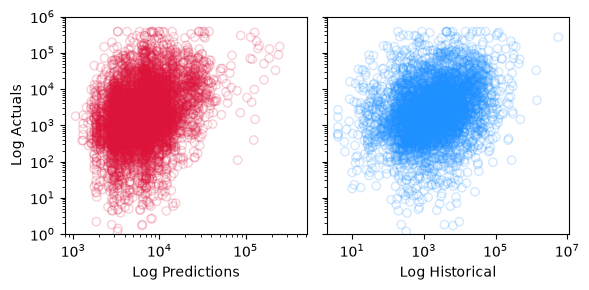

In [39]:
fig, axs = plt.subplots(1,2, figsize = (6, 3), sharey = True)
axs[0].scatter(df.preds_capped, df.actuals_capped, facecolor = 'NONE', edgecolor = 'crimson', alpha = .2)
axs[1].scatter(df.historical_spend, df.actuals_capped, facecolor = 'NONE', edgecolor = 'dodgerblue', alpha = .2)

axs[0].set_ylabel("Log Actuals")
axs[0].set_xlabel("Log Predictions")
axs[1].set_xlabel("Log Historical")

for ax in axs:
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_ylim([1e0, 1e6])

plt.tight_layout()

#### Both historical data and predictions appear to correlate with the actuals. We can do a simple correlation to get a sense
#### Also, it looks like capping and flooring didn't overly clip the data

In [40]:
df_target = df[["preds_capped", "actuals_capped", "historical_spend"]]
df_target.corr(method = "spearman") #spearman for non-linear relationship

,preds_capped,actuals_capped,historical_spend
preds_capped,1.000000,0.219089,0.335779
actuals_capped,0.219089,1.000000,0.276913
historical_spend,0.335779,0.276913,1.000000


#### Historicals correlate more strongly with actuals than predictions do
Prediction and historical both contain signal but this simple analysis suggests that historical spend contains more signal than the prediction does. We can investigate this further
I would not pay too much attention to the values themselves, but perhaps directionally it's worth noting

### 3.2 A possible proxy for blindness?

#### I want to create a crucial feature. Let's call it dt, being the number of days since last claim. This will be a proxy for blindness. Where the higher it is, the more "blind" a member's record is. The hypothesis then is that whatever metric we compute, some sort of error, should be higher when this is higher

In [41]:
latest_MX = pd.to_datetime(df_infer_MX.CLAIMLINE_FROM_DATE).groupby(df_infer_MX.MEMBER_TOKEN).max()
latest_RX = pd.to_datetime(df_infer_RX.FILL_DATE).groupby(df_infer_RX.MEMBER_TOKEN).max()

#now we can get time between proposal date and last bit of data that was able to be fed to get preds
df["last_claim"] = df.MEMBER_TOKEN.map(pd.concat([latest_MX, latest_RX], axis=1).max(axis=1))
df["proposal_date"] = pd.to_datetime(df.PROPOSAL_GENERATED_TIME, utc=True).dt.tz_localize(None).dt.normalize() #had to look this up!
df["delta_days"] = (df.proposal_date - df.last_claim).dt.days

df["gap_days"] = (pd.to_datetime(df.EFFECTIVE_DATE) - df.proposal_date).dt.days
df["gap"] = pd.cut(df.gap_days, [-1, 30, 90, 180, 1000], labels=["<=30d", "31-90d", "91-180d", ">180d"]) #bin edges
    #fixed after looking at distribution of gap days

conditions = [df.last_claim.isna(), df.delta_days <= 30, df.delta_days <= 90] #a month and 3 months seem like good
    #cutoffs. Not too high frequency, but not too low either. Remember that in np.select first choice is used
    #if both conditions met.
choices = ["no_claims", "0-30", "30-90"]
df["dt"] = np.select(conditions, choices, default="90+") 

In [42]:
df.dt.value_counts(dropna=False)

dt
no_claims    6347
90+          2987
0-30         2408
30-90        1625
Name: count, dtype: int64

#### About half of all folks have dt missing. 12% are considered more blind. It's good to not exclude any of these records because no claims itself could act as a baseline population.

### 3.3 Residuals

#### Let's look at the residuals as well

In [43]:
df["residuals"] = df.actual_spend - df.PREDICTIONS
df.residuals.describe()

count    1.336700e+04
mean    -2.077687e+03
std      3.007809e+04
min     -4.372463e+05
25%     -7.084438e+03
50%     -4.064581e+03
75%     -2.415226e+03
max      1.433965e+06
Name: residuals, dtype: float64

#### Since a lot of members have 0s for actuals, it makes sense that the residuals would be overwhelmingly negative

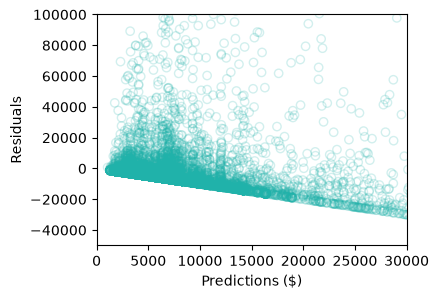

In [44]:
fig, ax = plt.subplots(figsize = (4,3))
ax.scatter(df.PREDICTIONS, df.residuals, facecolor = "None", edgecolor = "lightseagreen", alpha = .2)
#can't plot log because residuals can be negative
ax.set_xlim([0, 3e4])
ax.set_ylim([-5e4, 1e5])
ax.set_xlabel("Predictions ($)")
ax.set_ylabel("Residuals");

#### The residuals fall with the predictions. If model were well-calibrated residuals would be uncorrelated with prediction

In [45]:
df[["PREDICTIONS", "residuals"]].corr(method = "spearman")

,PREDICTIONS,residuals
PREDICTIONS,1.00000,-0.64861
residuals,-0.64861,1.00000


#### Let's look at pct_error for something a bit more normalized

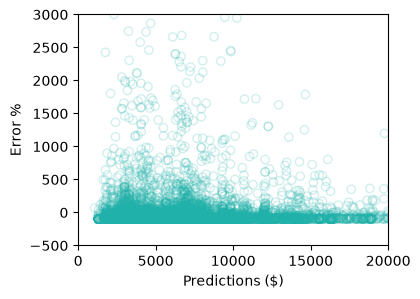

In [46]:
epsilon = 1e-5 #for numerical stability
pct_err = df.residuals/(df.PREDICTIONS + epsilon) * 100. 

fig, ax = plt.subplots(figsize = (4,3))
ax.scatter(df.PREDICTIONS, pct_err, facecolor = "None", edgecolor = "lightseagreen", alpha = .2)
#can't plot log because residuals can be negative
ax.set_xlim([0, 2e4])
ax.set_ylim([-5e2, 3e3])
ax.set_xlabel("Predictions ($)")
ax.set_ylabel("Error %");

In [47]:
df_target = df.copy()
df_target["pct_err"] = pct_err
df_target[["pct_err", "PREDICTIONS"]].corr(method = "spearman")

,pct_err,PREDICTIONS
pct_err,1.000000,-0.132498
PREDICTIONS,-0.132498,1.000000


#### Definitely attentuates it a bit when we normalize by the predictions themselves.

## 4. Segmentation

#### Where does the model go wrong? Look at $\sum$ actuals / $\sum$ preds within each segment

### 4.1 Defining segments and metric

In [48]:
df.columns

Index(['MEMBER_TOKEN', 'PLAN_DESIGN_ID', 'PROGRAM_ID', 'EFFECTIVE_DATE', 'AGE',
       'GENDER', 'RELATIONSHIP', 'STATE', 'PROPOSAL_GENERATED_TIME',
       'PREDICTIONS', 'RX_infer_tag', 'MX_infer_tag', 'RX_live_tag',
       'MX_live_tag', 'num_MX_RX_membership', 'MX_claimline_count',
       'MX_claim_count', 'MX_allowed_sum', 'MX_allowed_mean', 'MX_allowed_max',
       'MX_billed_sum', 'MX_billed_mean', 'MX_billed_max', 'MX_provider_count',
       'RX_claim_count', 'RX_allowed_sum', 'RX_allowed_mean', 'RX_allowed_max',
       'RX_unique_drugs', 'RX_unique_prescriber', 'RX_days_supply_sum',
       'RX_qty_mean', 'RX_qty_sum', 'MX_LIVE_allowed_max',
       'MX_LIVE_allowed_sum', 'MX_LIVE_allowed_mean', 'MX_LIVE_paid_sum',
       'MX_LIVE_claimline_count', 'RX_LIVE_allowed_max', 'RX_LIVE_allowed_sum',
       'RX_LIVE_allowed_mean', 'RX_LIVE_paid_sum', 'RX_LIVE_claim_count',
       'historical_spend', 'actual_spend', 'actuals_capped', 'preds_capped',
       'last_claim', 'proposal_date', 

#### We do not want segments to be too granular. Let's bin some features so segments are not too granular

In [49]:
df["pred_decile"] = pd.qcut(df.PREDICTIONS, q=10, labels = np.arange(10, 0, -1)) #prediction decile of 1 is highest
#for age, we can have baby/youth, young adult, adult, middle aged, senior 
df["age_group"] = pd.cut(df.AGE, [-1, 17, 34, 49, 64, 120], labels=["0-17", "18-34", "35-49", "50-64", "65+"])
df["hist_bin"] = pd.cut(df.historical_spend, [-np.inf, 0, 1000, 5000, np.inf], labels=["0", "1-1k", "1k-5k", ">5k"])
df["abs_err"] = (df.actuals_capped - df.preds_capped).abs() #compute this within each segment

#### Our segments will be:
- prediction decile
- blindness proxy (the one I am most excited to explore)
- age group
- gender
- any interactions of the ones above (e.g. age x gender)

In [50]:
threshold = 100 #we'll only consider segments where counts >= 100
denom = df.actuals_capped.sum() / df.preds_capped.sum()
print(f"overall A/E = {denom:.3f}")

#define a function where we create the A/E (actuals-to-expected ratio) table
def ae_table(segment):
    #each time aggregate at that segment level
    df_grouped = df.groupby(segment).agg(
        counts = ("MEMBER_TOKEN", "count"),
        sum_preds = ("preds_capped", "sum"),
        sum_actuals = ("actuals_capped", "sum"),
        MAE = ("abs_err", "mean")).reset_index()
    df_grouped["AE"] = df_grouped.sum_actuals / df_grouped.sum_preds
    df_grouped["AE_norm"] = df_grouped.AE / denom
    df_grouped = df_grouped[df_grouped.counts > threshold]
    return df_grouped

overall A/E = 0.685


#### First, let's start with single segments. Then we'll move to more granular segments

In [51]:
for segment in ["pred_decile", "dt", "gap", "age_group", "GENDER", "hist_bin"]:
    print(f"AE for {segment}")
    display(ae_table(segment))
    print("\n")

AE for pred_decile


,pred_decile,counts,sum_preds,sum_actuals,MAE,AE,AE_norm
0,10,1645,3.836098e+06,1.618387e+06,2551.839263,0.421884,0.615798
1,9,1044,3.121500e+06,1.725049e+06,3413.356668,0.552635,0.806647
2,8,1322,4.471248e+06,2.872297e+06,4269.266054,0.642393,0.937661
3,7,1336,5.439007e+06,3.869388e+06,5245.252373,0.711414,1.038408
4,6,1431,7.205333e+06,4.647392e+06,6228.690205,0.644993,0.941458
5,5,1243,7.847254e+06,7.335000e+06,8845.240465,0.934722,1.364357
6,4,1384,9.931475e+06,7.509314e+06,8792.893339,0.756113,1.103651
7,3,1330,1.114121e+07,9.096765e+06,11331.980983,0.816497,1.191791
8,2,1296,1.389013e+07,8.774198e+06,13076.259408,0.631686,0.922033
9,1,1336,3.197554e+07,2.028046e+07,25193.980883,0.634249,0.925775




AE for dt


,dt,counts,sum_preds,sum_actuals,MAE,AE,AE_norm
0,0-30,2408,3.173424e+07,2.721614e+07,16105.614824,0.857627,1.251826
1,30-90,1625,1.283168e+07,1.049565e+07,9867.758562,0.817948,1.193909
2,90+,2987,1.862162e+07,1.327648e+07,7521.311423,0.712960,1.040665
3,no_claims,6347,3.567126e+07,1.673999e+07,6441.490592,0.469285,0.684987




AE for gap


,gap,counts,sum_preds,sum_actuals,MAE,AE,AE_norm
0,<=30d,9718,7.196933e+07,6.045590e+07,9189.247642,0.840023,1.226131
1,31-90d,3496,2.615423e+07,7.270065e+06,8047.386648,0.277969,0.405734
2,91-180d,134,6.624530e+05,2.287360e+03,4926.609006,0.003453,0.005040


... (2 outputs left out)



AE for GENDER


,GENDER,counts,sum_preds,sum_actuals,MAE,AE,AE_norm
0,F,6522,5.423520e+07,3.775554e+07,9723.539766,0.696145,1.016120
1,M,6845,4.462360e+07,2.997271e+07,7998.655926,0.671678,0.980408




AE for hist_bin


,hist_bin,counts,sum_preds,sum_actuals,MAE,AE,AE_norm
0,0,6355,3.570823e+07,1.676454e+07,6438.617511,0.469487,0.685281
1,1-1k,2919,1.577907e+07,1.319571e+07,7274.711262,0.836279,1.220665
2,1k-5k,2238,1.509054e+07,1.406983e+07,8990.837172,0.932361,1.360911
3,>5k,1855,3.228096e+07,2.369817e+07,19349.830792,0.734122,1.071553


### 4.2 Segmentation Reads

#### Before going more granular, here are some trends:
1. dt and gap have clear trends! And it is as expected. A-E ratio is closer to 1 when dt and gap are small. Folks with no claims are overpredicted almost 2x than those with dt = 1-30 days. Have to explain why overprediction. 
2. pred_decile appears to have a weak trend too. Overpredictions happens more for top and bottom deciles, and model is most accurate in the middle deciles.

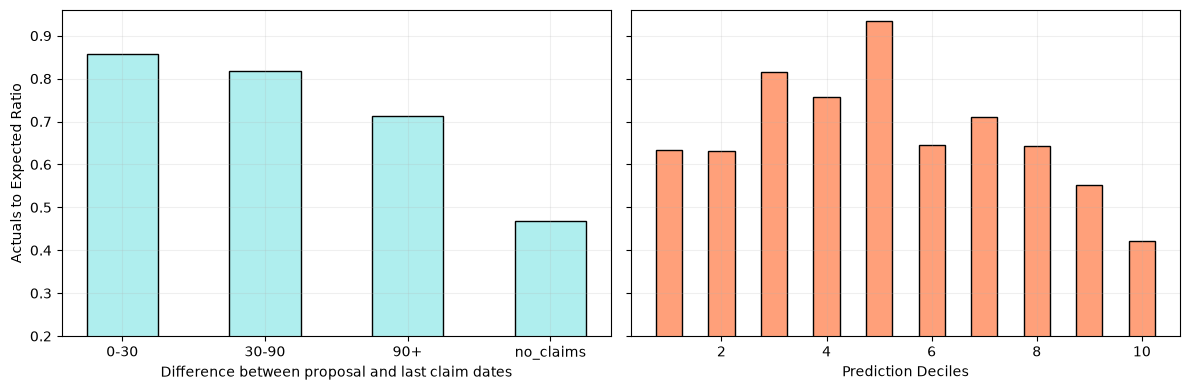

In [52]:
fig, axs = plt.subplots(1, 2, figsize = (12, 4), sharey=True)
for ax in axs:
    ax.grid(alpha=.2)

out_dt = ae_table("dt")
X = out_dt.dt
y = out_dt.AE
axs[0].bar(X, y, color = "paleturquoise", edgecolor = "k", width = .5)
axs[0].set_xlabel("Difference between proposal and last claim dates")

out_pred = ae_table("pred_decile")
X = out_pred.pred_decile
y = out_pred.AE
axs[1].bar(X, y, color = "lightsalmon", edgecolor = "k", width = .5)
axs[1].set_xlabel("Prediction Deciles")

axs[0].set_ylabel("Actuals to Expected Ratio")

for ax in axs:
    ax.set_ylim([.2, .96])

plt.tight_layout()
plt.show()

#### Is the prediction decile U-shape curve an artifact, or signal? Prediction itself is constructed from other characteristics. The lower deciles is probably made of a lot of no-claims, younger crowd which then leads to this overprediction. 
#### This motivates us to look at prediction decile x age and prediction decile x dt

In [53]:
for segment in [["pred_decile", "dt"], ["pred_decile", "age_group"]]:
    print(f"AE for {segment}")
    display(ae_table(segment))
    print("\n")

AE for ['pred_decile', 'dt']


,pred_decile,dt,counts,sum_preds,sum_actuals,MAE,AE,AE_norm
0,10,0-30,120,2.822960e+05,3.350952e+05,3872.163908,1.187035,1.732643
1,10,30-90,143,3.393815e+05,2.119153e+05,2533.082924,0.624416,0.911422
2,10,90+,353,8.246352e+05,4.327529e+05,2515.031746,0.524781,0.765991
3,10,no_claims,1029,2.389785e+06,6.386234e+05,2413.098984,0.267230,0.390060
6,9,90+,179,5.332282e+05,2.553934e+05,3068.360535,0.478957,0.699104
7,9,no_claims,736,2.203097e+06,7.753810e+05,2953.268462,0.351950,0.513721
10,8,90+,264,8.924201e+05,4.748465e+05,3779.387756,0.532089,0.776657
11,8,no_claims,870,2.944072e+06,1.811693e+06,4361.108116,0.615370,0.898218
12,7,0-30,165,6.619429e+05,1.118772e+06,8049.295291,1.690133,2.466985
13,7,30-90,181,7.207946e+05,5.625298e+05,4898.750833,0.780430,1.139146




AE for ['pred_decile', 'age_group']


,pred_decile,age_group,counts,sum_preds,sum_actuals,MAE,AE,AE_norm
0,10,0-17,616,1.357540e+06,7.385806e+05,2222.590042,0.544058,0.794129
1,10,18-34,948,2.272253e+06,7.179059e+05,2656.677358,0.315944,0.461165
3,9,0-17,650,1.944338e+06,1.018919e+06,3235.347027,0.524044,0.764915
4,9,18-34,319,9.441131e+05,5.813199e+05,3755.749140,0.615731,0.898745
6,8,0-17,659,2.182857e+06,2.038702e+06,4888.937318,0.933960,1.363245
7,8,18-34,615,2.122434e+06,7.265858e+05,3675.702546,0.342336,0.499687
10,7,0-17,188,7.409241e+05,5.465833e+05,4555.215902,0.737705,1.076783
11,7,18-34,510,2.115672e+06,1.559036e+06,5526.583316,0.736899,1.075606
12,7,35-49,585,2.364175e+06,1.391619e+06,4935.278413,0.588628,0.859184
16,6,18-34,529,2.729290e+06,1.136782e+06,5553.053530,0.416512,0.607957


#### In all 8 deciles that have both a 0–30 day cell and a no-claims cell, the 0–30 day group has the higher A/E.
#### Prediction x Age signals are mixed.

### 4.3 Tail behavior
#### A/E is a group average metric and we've focused on populations on whom the model overpredicts (A/E < 1). However, there are those who are in the tail and for whom the model underpredicts. 
#### E.g. if a member has a diagnosis revealed when live but has claims predicted when healthy, we'd underpredict. This is an example of blindness. Let's find such cases (assuming they exist) and see if they are disproportionately represented by those for whom blindness proxy is high (look at dt)

In [54]:
(df.actual_spend - df.PREDICTIONS).quantile(.95)

np.float64(10207.371585259381)

In [55]:
df["miss"] = df.actual_spend - df.PREDICTIONS
df["big_miss"] = df.miss > 10_000 #use the 95th perc as a heuristic cutoff. Could go higher             
df["miss_cost"] = np.where(df.big_miss, df.miss, 0)

def tail_table(data):
    df_grouped = data.groupby("dt").agg(
        counts = ("MEMBER_TOKEN", "count"),
        pct_any_live = ("actual_spend", lambda s: (s > 0).mean()),
        pct_big_miss = ("big_miss", "mean"),
        miss_cost = ("miss_cost", "sum")).reset_index()
    df_grouped["share_of_members"] = df_grouped.counts / df_grouped.counts.sum()
    df_grouped["share_of_miss_cost"] = df_grouped.miss_cost / df_grouped.miss_cost.sum()
    return df_grouped.round(3)

In [56]:
print("All members")
display(tail_table(df))
print("\n")

print("Quoted <=30d before effective date")
display(tail_table(df[df.gap == "<=30d"]))
print("\n")

print("A/E by dt, <=30d cohort")
display(df[df.gap == "<=30d"].groupby("dt").apply(\
    lambda g: g.actuals_capped.sum() / g.preds_capped.sum()))

All members


,dt,counts,pct_any_live,pct_big_miss,miss_cost,share_of_members,share_of_miss_cost
0,0-30,2408,0.674,0.096,1.787681e+07,0.180,0.410
1,30-90,1625,0.598,0.073,6.564509e+06,0.122,0.151
2,90+,2987,0.546,0.050,7.647565e+06,0.223,0.175
3,no_claims,6347,0.382,0.028,1.152559e+07,0.475,0.264




Quoted <=30d before effective date


,dt,counts,pct_any_live,pct_big_miss,miss_cost,share_of_members,share_of_miss_cost
0,0-30,1834,0.783,0.109,1.616163e+07,0.189,0.410
1,30-90,1205,0.714,0.088,5.990028e+06,0.124,0.152
2,90+,2176,0.664,0.060,6.793517e+06,0.224,0.172
3,no_claims,4503,0.484,0.035,1.050236e+07,0.463,0.266




A/E by dt, <=30d cohort


dt
0-30         1.014446
30-90        1.018287
90+          0.881012
no_claims    0.589102
dtype: float64

#### Blind population is under-represented in the big misses population, not over-represented
#### In other words, rate of big misses falls as blindness increases
#### Based on the clean cohort (low gap), the model is well calibrated for members with a claim in the last 90 days, and the over-prediction is concentrated in the "blind" groups.

## 5. Conclusions

## Findings: does blindness affect member-level predictions?

**What is blindness?** 

$\rightarrow$ Arlo develops a model that predicts annual claims cost for a member
from both medical and pharma. This model is scored from claim that lagged. If a 
member has a condition that already existed then but didn't show until later (live)
then that is a form of blindness. It is a gap between what the member had and what
the model used. 

**Is it important?**

$\rightarrow$ Blindness (or at least its proxy) does affect calibration. We computed 
A/E (actual-to-predicted ratio) after adjusting for annualized actuals and capping at
same dollar value, obtaining an overall A/E of 0.685, but this could range a lot from
segment-to-segment, e.g. 0.47 in the segment containing members with no visible claims,
but 0.86 in segment with a claim in the 30 days before the quote (i.e. a less blind /
more visible segment).

**How?**

$\rightarrow$ The score is mostly a function of what it can see: the lowest-predicted decile is
63% no-claims members versus 16% in the highest. Where recent claims are visible it is well
calibrated (A/E about 1.0 for a claim in the last 90 days, among members quoted within 30
days of the effective date). Where little is visible it over-predicts (A/E 0.88 with no claim
in 90+ days, 0.59 with no claims at all). So blindness shows up mainly as over-prediction
of low-visibility members, plus a smaller tail of hidden-condition members who are under-predicted.

**Tail behavior.**

$\rightarrow$ Members with no visible claims or none in 90+ days account for 70% of all 
members, but they only account for 44% of those for whom underprediction is > \\$10000.
Same findings in the clean cohort. 178 members that are no-claims account for \\$11.5 MM
being underpredicted. That is a significant level of mispricing. These misses include
new/unseen onset, so we may quantify this as an upper bound on blindness-driven
under-prediction.

### Evidence (refer to section 4.2)
- A/E by days since last claim (dt): 0-30 day 0.86 (n=2,408); 30-90 day 0.82 (1,625);
  90+ day 0.71 (2,987); no claims 0.47 (6,347).
  
- Within prediction decile, 0-30 day vs no-claims A/E ratio is > 1 in 8 of 8 deciles
  with both cells (range 1.5x-4.4x).

- Quote-to-effective-date gap: members quoted <=30 days before Jan 1 have A/E 0.84
  (73% of members). Those quoted 31-90 days before have 0.28, and 91-180 days approx 0.00,
  even though predictions per member are similar (~\\$7.4k vs \\$6.2k realized, $2.1k realized).
  I did not verify why. Perhaps it is an exposure/enrollment effect rather than
  model error, so the overall 0.685 probably understates calibration among enrolled members.

### What I would change in the pipeline
1. Add recency features in the model itself (e.g. days since last claim).
2. Make sure to include forward looking cohorts as out-of-time test sample. So the model is
   trained and evaluated in-time but also evaluated out-of-time. This will ensure robustness
   of the model.
3. Multiplicative correction factors by visibility segment (no-claims A/E is 0.59 even in
   the clean cohort), or isotonic regression on the score. First fix the overall level
   (see limits)

### Limits
- Actuals are six months annualized x2 and June claims may be incomplete (I did not check
  run-out), so absolute A/E levels are uncertain. I rely on relative comparisons across segments.
- The dollar basis of the prediction (allowed vs paid) is unknown.
- No confidence intervals; members within a program are correlated, and cells of 100-200
  members are noisy. The 8-of-8 consistency across deciles is my robustness argument.
- New onset and post-enrollment catch-up care are not separated, and there are no
  enrollment or termination dates, so zero-claim members could be non-enrolled.
  
### Confidence
- **High:** A/E falls as visible data shrinks, and this holds within prediction
  deciles (8 of 8).
- **Medium:** that this reflects how the model handles missing data. No-claims members may
  also be new to coverage, healthy, or not enrolled.
- **Low:** the size of lag-driven blindness itself. I have no direct measure of missing
  claims (inference has no paid/received dates), so I used days since last claim as a proxy.
  
### Follow-ups
- I would look at a lag curve on weekly level, if I had more time. Wonder if I could also
  use a random forest classifier to predict tail behavior (maybe not because there is lots of
  noise and low power).